# Wine Quality Prediction 

**Name:** Mohini More  
**Organization:** Oasis Infobyte  
**Internship Track:** Data Analytics  
**Task:** Level 2 — Task 2  
**Tools Used:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Jupyter Notebook

## Project Objective

The objective of this project is to predict wine quality using its physicochemical properties.

The project includes data exploration, visualization, feature engineering, classification model training, and evaluation. Random Forest, SGD Classifier, and Support Vector Classifier (SVC) will be compared to identify a suitable model for predicting wine quality.

## 1. Import Libraries and Load the Dataset



In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("C:/OASIS Data Analytics Project/Task_2_winequalityN.csv")
df.head()

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


## 2. Understanding the Dataset



In [3]:
#  The number of rows and columns
print("Dataset Shape:", df.shape)

# column names
print("\nColumn Names:")
print(df.columns)

# data types and non-null values
print("\nDataset Information:")
df.info()

# missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (6497, 13)

Column Names:
Index(['type', 'fixed acidity', 'volatile acidity', 'citric acid',
       'residual sugar', 'chlorides', 'free sulfur dioxide',
       'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol',
       'quality'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  6497 non-null   str    
 1   fixed acidity         6487 non-null   float64
 2   volatile acidity      6489 non-null   float64
 3   citric acid           6494 non-null   float64
 4   residual sugar        6495 non-null   float64
 5   chlorides             6495 non-null   float64
 6   free sulfur dioxide   6497 non-null   float64
 7   total sulfur dioxide  6497 non-null   float64
 8   density               6497 non-null   float64
 9   pH                    6488 non-null  

## 3. Descriptive Statistical Analysis



In [4]:
# Descriptive statistics
df.describe().round(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6487.00,6489.00,6494.00,6495.00,6495.00,6497.00,6497.00,6497.00,6488.00,6493.00,6497.00,6497.00
mean,7.22,0.34,0.32,5.44,0.06,30.53,115.74,0.99,3.22,0.53,10.49,5.82
std,1.30,0.16,0.15,4.76,0.04,17.75,56.52,0.00,0.16,0.15,1.19,0.87
min,3.80,0.08,0.00,0.60,0.01,1.00,6.00,0.99,2.72,0.22,8.00,3.00
25%,6.40,0.23,0.25,1.80,0.04,17.00,77.00,0.99,3.11,0.43,9.50,5.00
50%,7.00,0.29,0.31,3.00,0.05,29.00,118.00,0.99,3.21,0.51,10.30,6.00
75%,7.70,0.40,0.39,8.10,0.06,41.00,156.00,1.00,3.32,0.60,11.30,6.00
max,15.90,1.58,1.66,65.80,0.61,289.00,440.00,1.04,4.01,2.00,14.90,9.00


## 4. Distribution of Wine Quality Scores

In this step, we examine how frequently each wine quality score occurs in the dataset. This helps us identify common and underrepresented quality classes.

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64


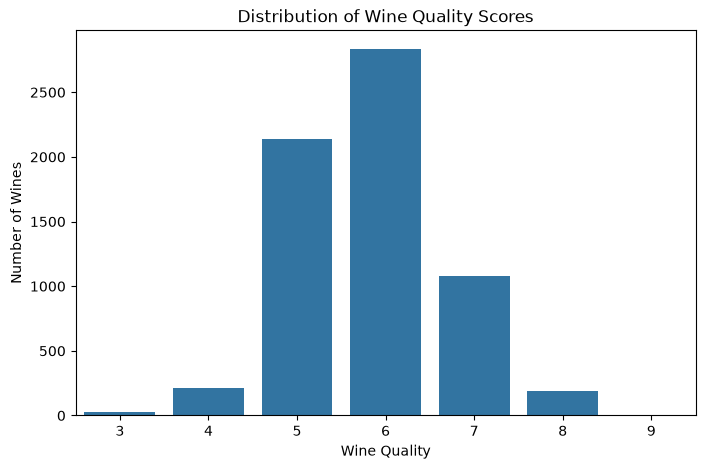

In [5]:
# Count the frequency of each quality score
print(df["quality"].value_counts().sort_index())

# Visualize the quality score distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality")

plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Wine Quality")
plt.ylabel("Number of Wines")
plt.show()

### Interpretation of Wine Quality Distribution

The bar chart shows the distribution of wine quality scores in the dataset.

- Quality score **6** has the highest number of wine samples.
- Quality score **5** is the second most frequent category.
- Quality score **7** also has a considerable number of samples.
- Quality scores **3, 4, and 8** have relatively fewer observations.
- Quality score **9** has very few or no observations.

**Key Findings:**

Most wine samples have quality scores between 5 and 7. The distribution is concentrated around scores 5 and 6, while the lower and higher quality categories are underrepresented.

This indicates class imbalance in the original quality scores. Therefore, converting the quality scores into broader categories, such as Good and Bad, can make the classification task more manageable.

## 5. Distribution of Physicochemical Features

In this step, we visualize the distributions of the physicochemical properties of wine to understand their patterns, spread, and possible skewness.

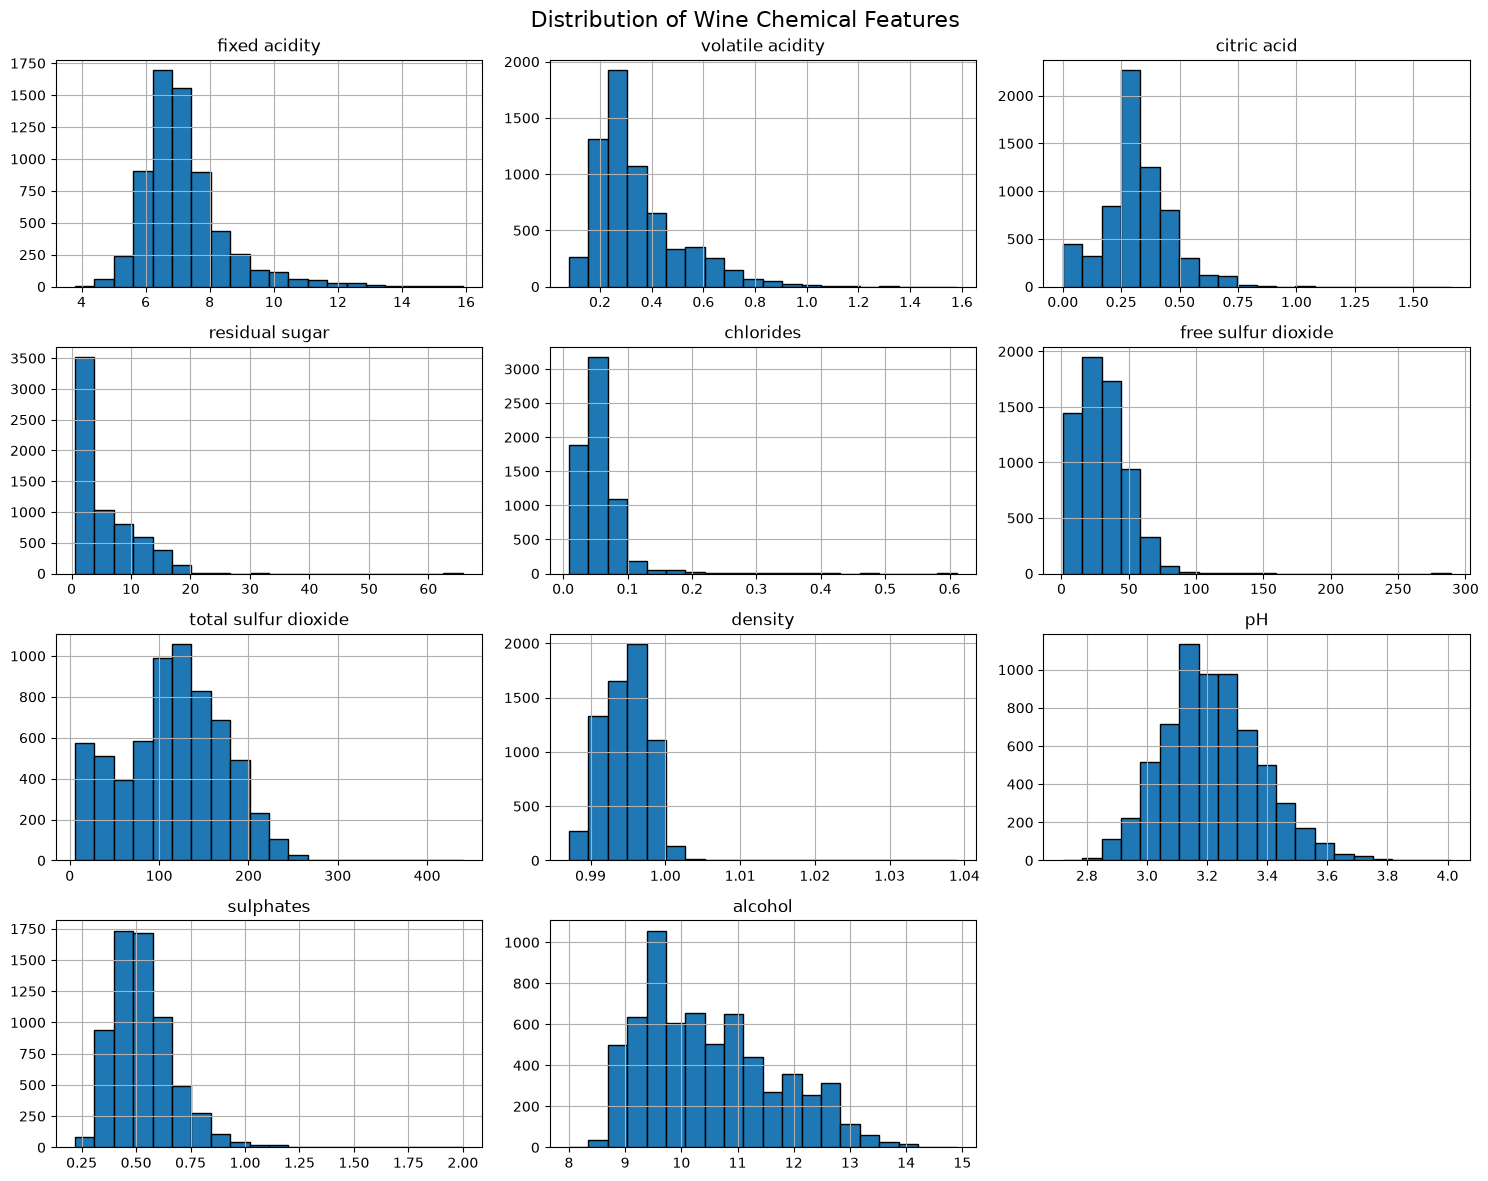

In [6]:
# Select numerical columns excluding the quality target
numeric_features = df.select_dtypes(include=np.number).columns.drop("quality")

# Plot histograms for all numerical features
df[numeric_features].hist(figsize=(15, 12), bins=20, edgecolor="black")

plt.suptitle("Distribution of Wine Chemical Features", fontsize=16)
plt.tight_layout()
plt.show()

### Interpretation of Chemical Feature Distributions

The histograms show the distribution of different chemical properties of wine.

- Most features have values concentrated within specific ranges.
- Volatile acidity, residual sugar, and chlorides show right-skewed distributions.
- Density and pH values are concentrated within relatively narrow ranges.
- Alcohol content is mostly distributed between 9% and 12%.

Overall, the distributions help us understand the variation in wine properties and identify possible extreme values before model building.

## 6. Correlation Analysis



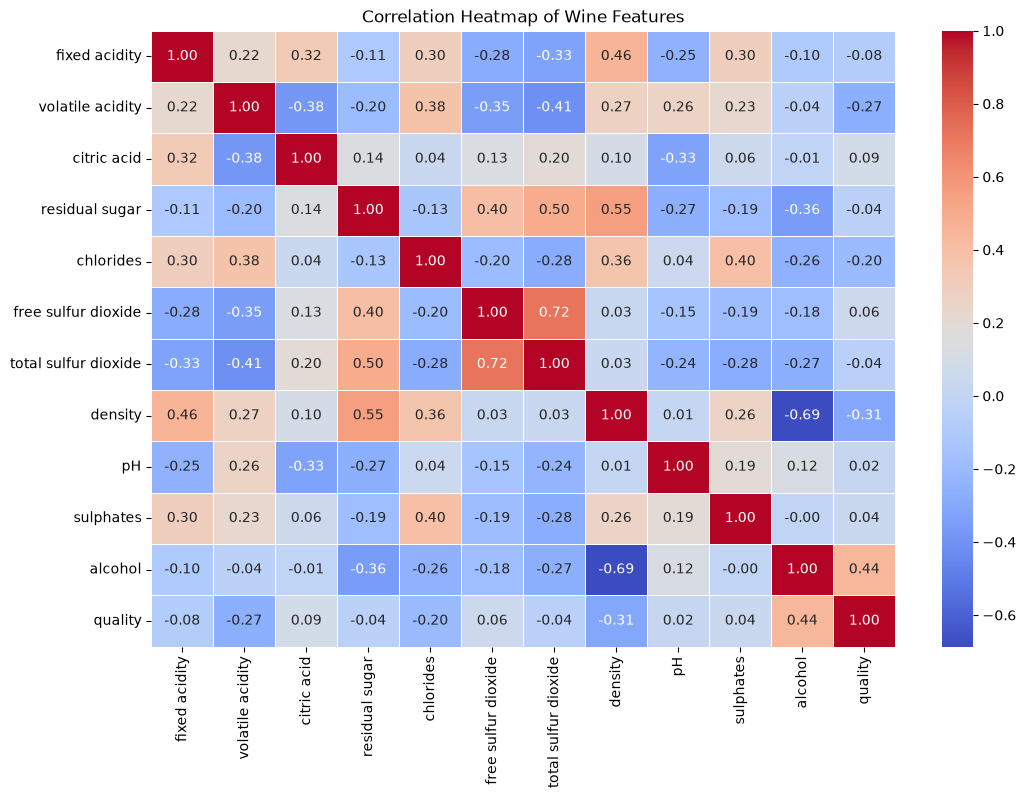

In [7]:
# Calculate correlation between numerical columns
correlation = df.select_dtypes(include=np.number).corr()

# Create correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Wine Features")
plt.show()

### Interpretation of Correlation Heatmap

- Alcohol has the strongest positive correlation with wine quality (0.44).
- Density (-0.31) and volatile acidity (-0.27) show negative correlations with quality.
- Most other features have weak correlations with wine quality.
- Free sulfur dioxide and total sulfur dioxide show a strong positive correlation (0.72).

Overall, alcohol has the strongest positive association with wine quality among the features, while density shows a negative association. Correlation does not imply causation.

## 7. Data Cleaning and Missing Value Treatment



In [8]:
# Check missing values before treatment
print("Missing values before treatment:")
print(df.isnull().sum())

# Fill numerical missing values with median
for column in df.select_dtypes(include=np.number).columns:
    df[column] = df[column].fillna(df[column].median())

# Fill categorical missing values with mode
for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].fillna(df[column].mode()[0])

# Check missing values after treatment
print("\nMissing values after treatment:")
print(df.isnull().sum())

Missing values before treatment:
type                     0
fixed acidity           10
volatile acidity         8
citric acid              3
residual sugar           2
chlorides                2
free sulfur dioxide      0
total sulfur dioxide     0
density                  0
pH                       9
sulphates                4
alcohol                  0
quality                  0
dtype: int64

Missing values after treatment:
type                    0
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


C:\Users\DELL\AppData\Local\Temp\ipykernel_24832\2458975827.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include="object").columns:


## 8. Feature Engineering – Wine Quality Classification

The original wine quality scores are converted into two categories:

- Bad Wine (0): Quality score below 6.
- Good Wine (1): Quality score of 6 or above.

This conversion simplifies the prediction task into a binary classification problem.

In [9]:
# Convert quality scores into binary categories
df["quality_label"] = (df["quality"] >= 6).astype(int)

# Display the first five rows
df[["quality", "quality_label"]].head()

,quality,quality_label
0,6,1
1,6,1
2,6,1
3,6,1
4,6,1


quality_label
1    4113
0    2384
Name: count, dtype: int64

Class Distribution (%):
quality_label
1    63.31
0    36.69
Name: proportion, dtype: float64


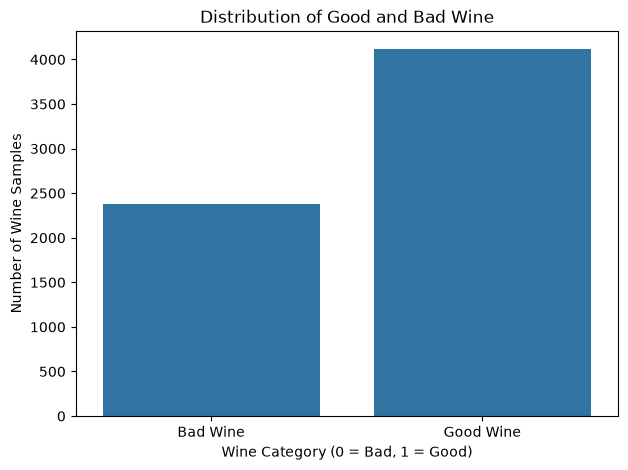

In [10]:
# Count Good and Bad wine samples
print(df["quality_label"].value_counts())

# Display percentages
print("\nClass Distribution (%):")
print((df["quality_label"].value_counts(normalize=True) * 100).round(2))

# Visualize the new categories
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="quality_label")

plt.title("Distribution of Good and Bad Wine")
plt.xlabel("Wine Category (0 = Bad, 1 = Good)")
plt.ylabel("Number of Wine Samples")
plt.xticks([0, 1], ["Bad Wine", "Good Wine"])
plt.show()

### Interpretation of Good and Bad Wine Distribution

The chart shows that:

- Good wine samples (quality ≥ 6) are approximately 63.5% of the dataset.
- Bad wine samples (quality < 6) are approximately 36.5%.
- Good wine samples are more frequent than bad wine samples.

This indicates a moderate class imbalance. Therefore, stratified sampling will be used to maintain the class proportions during model training and testing.

## 9. Feature Selection and Data Preparation

The physicochemical properties of wine are selected as input features, while the newly created quality label is used as the target variable.

The categorical wine type is converted into numerical format using One-Hot Encoding.

In [11]:
# Separate input features and target variable
X = df.drop(["quality", "quality_label"], axis=1)
y = df["quality_label"]

# Convert categorical features into numerical format
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Display the prepared data
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

X.head()

Feature Shape: (6497, 12)
Target Shape: (6497,)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,type_white
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,1
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,1
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,1
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,1
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,1


## 10. Splitting the Dataset into Training and Testing Sets

The dataset is divided into 80% training data and 20% testing data.

Stratified sampling is used to maintain the proportion of Good and Bad wine samples in both datasets. A random state is set to ensure reproducibility.

In [12]:
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the shapes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (5197, 12)
Testing Features: (1300, 12)
Training Target: (5197,)
Testing Target: (1300,)


## 11. Model Training

Three classification algorithms are selected for predicting wine quality:

- Random Forest Classifier
- SGD Classifier
- Support Vector Classifier (SVC)

StandardScaler is applied to the SGD and SVC models because they are sensitive to differences in feature scales. Random Forest is trained without feature scaling.

In [13]:
# Random Forest algorithm for classification
from sklearn.ensemble import RandomForestClassifier

# SGD algorithm for classification
from sklearn.linear_model import SGDClassifier

# Support Vector Classifier for classification
from sklearn.svm import SVC

# Pipeline to combine preprocessing and model steps
from sklearn.pipeline import Pipeline

# StandardScaler to standardize feature values
from sklearn.preprocessing import StandardScaler

# Initialize the models
models = {
    "Random Forest": RandomForestClassifier(
        random_state=42
    ),

    "SGD Classifier": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SGDClassifier(random_state=42))
    ]),

    "SVC": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC())
    ])
}

# Train all three models
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "training completed.")

Random Forest training completed.
SGD Classifier training completed.
SVC training completed.


## 12. Model Evaluation

In this step, we evaluate the performance of the three trained classification models using accuracy, precision, recall, and F1-score.

These metrics help us compare the models and understand how effectively they classify Good and Bad wine samples.

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Evaluate each trained model
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

# Display model comparison
results_df = pd.DataFrame(results)
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.8262,0.8443,0.8894,0.8663
1,SGD Classifier,0.7054,0.7696,0.7631,0.7663
2,SVC,0.7577,0.7810,0.8578,0.8176


### Interpretation of Model Performance

- Random Forest achieved the highest accuracy (82.62%) and F1-score (0.8663).
- SVC achieved an accuracy of 75.77% and an F1-score of 0.8176.
- SGD Classifier showed the lowest performance, with an accuracy of 70.54%.
- Random Forest also achieved the highest precision (0.8443) and recall (0.8894).

Overall, Random Forest performed better than the other two models and is the most suitable model among those evaluated for this dataset.

## 13. Classification Report

The classification report evaluates each model using precision, recall, F1-score, and support for both wine categories.

It helps us understand how effectively each model identifies Bad and Good wine samples.

In [15]:
from sklearn.metrics import classification_report

# Generate classification reports
for name, model in models.items():
    print("\nClassification Report for:", name)
    y_pred = model.predict(X_test)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["Bad Wine", "Good Wine"]
    ))


Classification Report for: Random Forest
              precision    recall  f1-score   support

    Bad Wine       0.79      0.72      0.75       477
   Good Wine       0.84      0.89      0.87       823

    accuracy                           0.83      1300
   macro avg       0.82      0.80      0.81      1300
weighted avg       0.82      0.83      0.82      1300


Classification Report for: SGD Classifier
              precision    recall  f1-score   support

    Bad Wine       0.60      0.61      0.60       477
   Good Wine       0.77      0.76      0.77       823

    accuracy                           0.71      1300
   macro avg       0.68      0.68      0.68      1300
weighted avg       0.71      0.71      0.71      1300


Classification Report for: SVC
              precision    recall  f1-score   support

    Bad Wine       0.70      0.58      0.64       477
   Good Wine       0.78      0.86      0.82       823

    accuracy                           0.76      1300
   macro av

### Interpretation of Classification Reports

- Random Forest achieved the best overall performance among the three models.
- It performed well in identifying Good Wine samples, with an F1-score of 0.87.
- SGD Classifier showed the lowest overall performance.
- SVC performed better than SGD but had a lower recall for Bad Wine samples.

Overall, Random Forest provides the best balance of classification performance among the three models.

## 14. Confusion Matrix

A confusion matrix is used to evaluate the classification performance of each model by comparing actual wine categories with predicted categories.

It shows correct and incorrect predictions for Bad Wine and Good Wine.

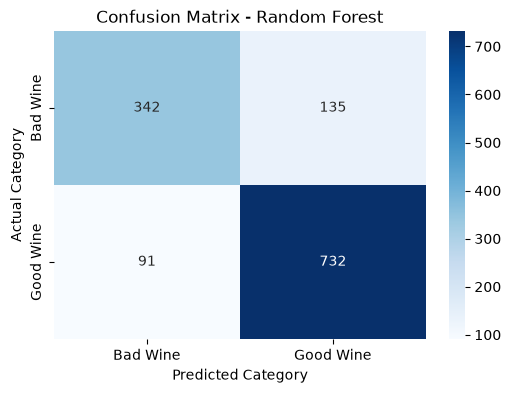

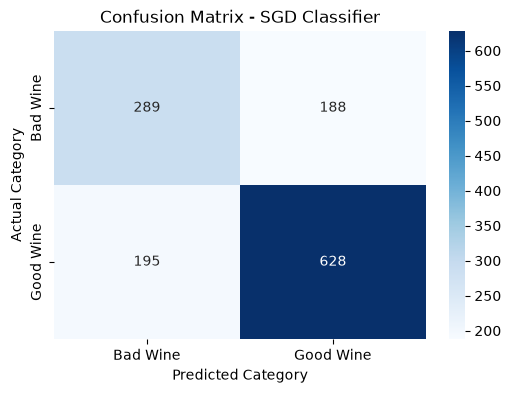

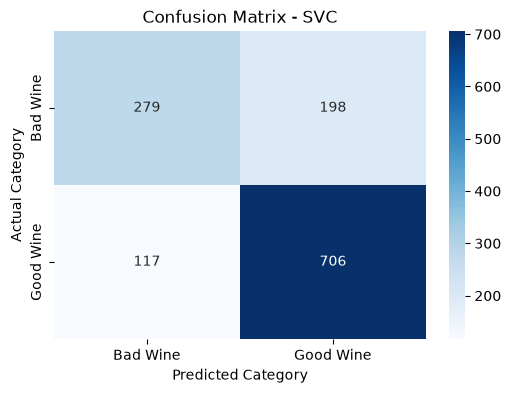

In [16]:
from sklearn.metrics import confusion_matrix

# Generate confusion matrices for all models
for name, model in models.items():
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Bad Wine", "Good Wine"],
        yticklabels=["Bad Wine", "Good Wine"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Category")
    plt.ylabel("Actual Category")
    plt.show()

Interpretation of Confusion Matrices
Random Forest
- Correctly classified 342 Bad Wine and 732 Good Wine samples.
- Incorrectly classified 135 Bad Wine as Good Wine and 91 Good Wine as Bad Wine.
- It has the highest number of correct predictions.
SGD Classifier
- Correctly classified 289 Bad Wine and 628 Good Wine samples.
- Made more incorrect predictions than the other models.
SVC
- Correctly classified 279 Bad Wine and 706 Good Wine samples.
- Performed better than SGD in identifying Good Wine, but had more errors overall.
Overall: Random Forest achieved the best results, with 1,074 correct predictions out of 1,300 test samples.

## 15. Feature Importance

Feature importance helps identify which chemical properties contribute most to the Random Forest model's predictions.

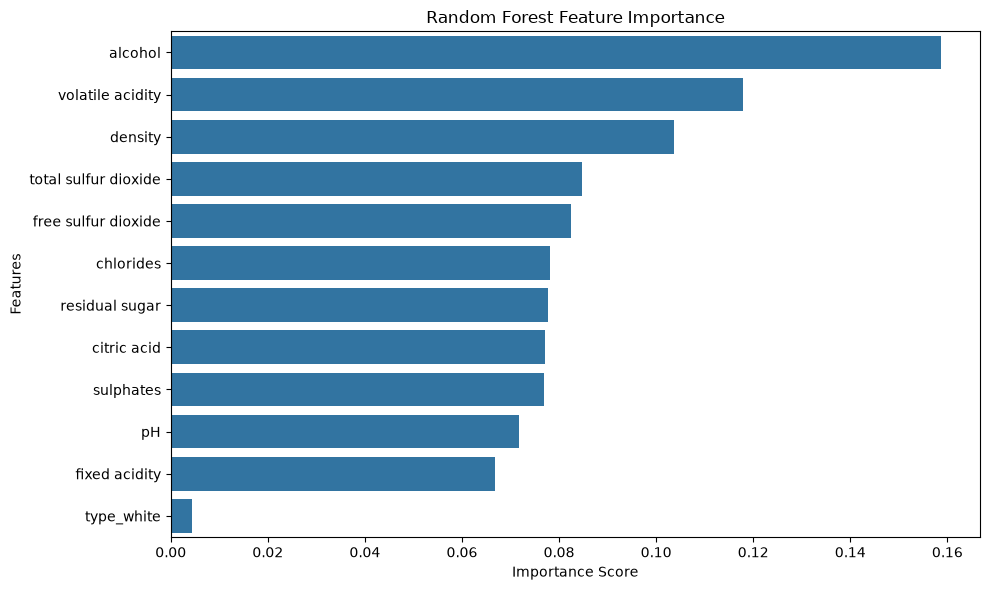

In [17]:
# Get the trained Random Forest model
rf_model = models["Random Forest"]

# Calculate feature importance
importances = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

# Plot feature importance
plt.figure(figsize=(10, 6))
sns.barplot(x=importances.values, y=importances.index)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

## 16. Model Comparison

The performance of Random Forest, SGD Classifier, and Support Vector Classifier (SVC) is compared using accuracy, precision, recall, and F1-score.

In [18]:
# Display model comparison
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.8262,0.8443,0.8894,0.8663
1,SGD Classifier,0.7054,0.7696,0.7631,0.7663
2,SVC,0.7577,0.7810,0.8578,0.8176


### Interpretation of Model Comparison

- Random Forest achieved the highest accuracy of 82.62%.
- Random Forest also achieved the highest F1-score of 0.8663.
- SVC achieved 75.77% accuracy and performed better than SGD Classifier.
- SGD Classifier recorded the lowest accuracy of 70.54%.

Overall, Random Forest performed best among the three models based on accuracy, precision, recall, and F1-score.

## 17. Predicting Wine Quality for a New Sample

The trained Random Forest model is used to predict the quality category of a new wine sample based on its chemical properties.



In [21]:
# Create a new wine sample
new_wine = pd.DataFrame([{
    "fixed acidity": 7.0,
    "volatile acidity": 0.30,
    "citric acid": 0.30,
    "residual sugar": 2.0,
    "chlorides": 0.05,
    "free sulfur dioxide": 20.0,
    "total sulfur dioxide": 50.0,
    "density": 0.995,
    "pH": 3.2,
    "sulphates": 0.60,
    "alcohol": 11.5,
    "type_white": 1
}])

# Predict using the trained Random Forest model
prediction = rf_model.predict(new_wine)

if prediction[0] == 1:
    print("Predicted Category: Good Wine")
else:
    print("Predicted Category: Bad Wine")

Predicted Category: Good Wine


In [22]:
# Display prediction probabilities
probabilities = rf_model.predict_proba(new_wine)

print("Probability of Bad Wine:", round(probabilities[0][0] * 100, 2), "%")
print("Probability of Good Wine:", round(probabilities[0][1] * 100, 2), "%")

Probability of Bad Wine: 19.0 %
Probability of Good Wine: 81.0 %


## 18. Overall Conclusion

In this project, wine quality prediction was performed using machine learning classification techniques based on the physicochemical properties of wine.

The dataset was explored, cleaned, and prepared for model training. Exploratory Data Analysis helped identify patterns, distributions, and relationships between different chemical features and wine quality.

Three classification algorithms were implemented and evaluated: Random Forest, SGD Classifier, and Support Vector Classifier (SVC).

Among these models, **Random Forest performed the best**, achieving 82.62% accuracy and an F1-score of 0.8663. Alcohol, volatile acidity, and density were identified as important features influencing the model's predictions.

The trained Random Forest model was also used to predict a new wine sample, classifying it as Good Wine with an estimated probability of 81%.

Overall, this project provided practical experience in data preprocessing, exploratory data analysis, feature engineering, machine learning classification, model evaluation, and making predictions on new data.